# ECS708U/P Machine Learning Coursework — Understanding Visual Data (Fashion-MNIST)

**Research question.** What structure exists in Fashion-MNIST, how can different machine-learning
models exploit that structure, and what do their successes and failures teach us about the data
and its representations?

This notebook runs top to bottom with *Restart and run all*. Expensive steps (MLP training)
are cached in `results/`; delete `results/runs/` and `results/checkpoints/` to retrain from scratch.

**Data roles (R1).** Train → fit parameters and scalers. Validation → every choice
(hyperparameters, checkpoints, K, thresholds). Test → used once, at the end, after the test plan is frozen.
Parts 0–3 below therefore report **validation** results only.

## Part 0 — Setup: data and computing (0.1, 0.2)

In [1]:
import json
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch

from src.data import CLASS_NAMES, SPLIT_SEED, get_splits, load_fashion_mnist
from src.register import log_experiment, show_register

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
pd.set_option("display.precision", 3)

FIG_DIR = "figures"
def savefig(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", bbox_inches="tight", dpi=120)

# 0.2 Record the hardware and software used
print("Machine :", platform.machine(), "|", platform.processor() or "", "| OS:", platform.platform())
print("Python  :", platform.python_version())
print("torch", torch.__version__, "| sklearn", sklearn.__version__, "| numpy", np.__version__)
print("Compute : CPU only (torch threads = %d)" % torch.get_num_threads())

Machine : arm64 | arm | OS: macOS-26.6.2-arm64-arm-64bit
Python  : 3.11.7
torch 2.15.0 | sklearn 1.9.1 | numpy 2.4.6
Compute : CPU only (torch threads = 6)


### 0.1 Fixed data partitions

* The official 60,000 training images are split **stratified** into 50,000 train / 10,000 validation
  with `SPLIT_SEED = 708`. Indices are saved in `splits/splits.npz` and only ever loaded afterwards.
* **CPU-friendly option:** all supervised models in this notebook are fitted on a fixed stratified
  **10,000-image subset of the training partition** (`train_sub`). Validation and test sets are the full
  10,000 images. Using the subset keeps every experiment fast enough to repeat with several seeds,
  and it makes overfitting easier to observe.
* Clustering / feature-extraction subsets: 3,000 train (from the train partition), 1,000 validation
  (from the validation partition) and 1,000 test (from the official test set). The same images are
  used for every representation.
* Labels are used **only** to stratify. Pixel values are rescaled by the fixed constant 1/255,
  which is not learned from data and therefore cannot leak information.

In [2]:
t0 = time.time()
X_off, y_off, X_test, y_test = load_fashion_mnist()
splits = get_splits(y_off, y_test)
print(f"Loaded in {time.time() - t0:.1f}s; split seed = {int(splits['seed'][0])}")

X_tr, y_tr = X_off[splits["train_sub"]], y_off[splits["train_sub"]]   # fitting set (10k)
X_val, y_val = X_off[splits["val"]], y_off[splits["val"]]             # model selection (10k)
# X_test / y_test stay untouched until the final, frozen evaluation.

# Sanity checks: partitions are disjoint and inside the right sets
assert len(np.intersect1d(splits["train"], splits["val"])) == 0
assert np.isin(splits["train_sub"], splits["train"]).all()
assert np.isin(splits["cluster_train"], splits["train"]).all()
assert np.isin(splits["cluster_val"], splits["val"]).all()

sizes = {k: len(v) for k, v in splits.items() if k != "seed"}
counts = pd.DataFrame({
    "train (50k)": np.bincount(y_off[splits["train"]]),
    "val": np.bincount(y_val),
    "train_sub (fit)": np.bincount(y_tr),
    "cluster_train": np.bincount(y_off[splits["cluster_train"]]),
    "cluster_val": np.bincount(y_off[splits["cluster_val"]]),
    "cluster_test": np.bincount(y_test[splits["cluster_test"]]),
    "test": np.bincount(y_test),
}, index=CLASS_NAMES)
counts.loc["TOTAL"] = counts.sum()
print("Partition sizes:", sizes)
counts

Loaded in 0.7s; split seed = 708
Partition sizes: {'train': 50000, 'val': 10000, 'train_sub': 10000, 'cluster_train': 3000, 'cluster_val': 1000, 'cluster_test': 1000}


,train (50k),val,train_sub (fit),cluster_train,cluster_val,cluster_test,test
T-shirt/top,5000,1000,1000,300,100,100,1000
Trouser,5000,1000,1000,300,100,100,1000
Pullover,5000,1000,1000,300,100,100,1000
Dress,5000,1000,1000,300,100,100,1000
Coat,5000,1000,1000,300,100,100,1000
Sandal,5000,1000,1000,300,100,100,1000
Shirt,5000,1000,1000,300,100,100,1000
Sneaker,5000,1000,1000,300,100,100,1000
Bag,5000,1000,1000,300,100,100,1000
Ankle boot,5000,1000,1000,300,100,100,1000


**Table 0.1 (addresses 0.1).** Images per class in every partition. Each class is exactly 10% of every
partition, so stratification preserved the (already balanced) class proportions.

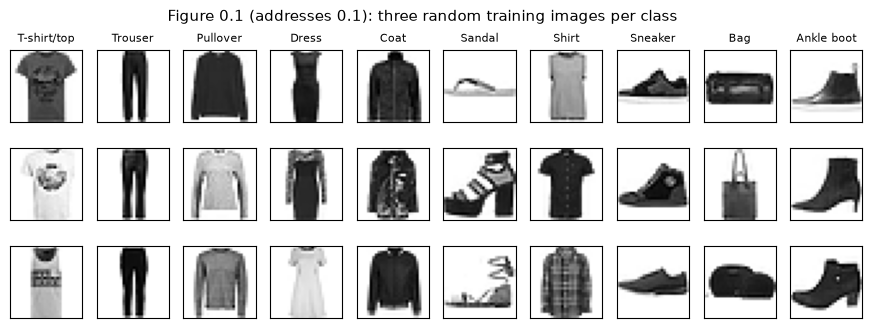

In [3]:
fig, axes = plt.subplots(3, 10, figsize=(11, 3.6))
rng = np.random.default_rng(0)
for c in range(10):
    idx = rng.choice(np.where(y_tr == c)[0], 3, replace=False)
    for r in range(3):
        ax = axes[r, c]
        ax.imshow(X_tr[idx[r]].reshape(28, 28), cmap="gray_r")
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if r == 0:
            ax.set_title(CLASS_NAMES[c], fontsize=8)
fig.suptitle("Figure 0.1 (addresses 0.1): three random training images per class")
savefig(fig, "fig0_1_examples")
plt.show()

Even from a few examples, the upper-body classes (T-shirt/top, Pullover, Coat, Shirt) look alike:
similar silhouettes with differences in sleeves, collars and texture. Footwear (Sandal, Sneaker,
Ankle boot) forms a second visually related group. We expect most confusions inside these groups.